# 02 - Módulo 1: Identificación de Mosquitos con Redes Convolucionales (CNN)

**Proyecto 2: VectorIA** 

En este notebook se desarrolla el Módulo 1 para identificar la especie de mosquito a partir de fotografías:
- **Aedes aegypti** (vector principal del dengue)
- **Aedes albopictus** (vector secundario)
- **Culex** (mosquito común, no transmite dengue)


# 1.Importación librerías


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.image import imread
import warnings
warnings.filterwarnings('ignore')


# 2.Importación fuente de datos


In [2]:
# Directorio donde se encuentran las carpetas de las 3 especies
data_path = '../data/raw/images/'
os.listdir(data_path)


['Aedes aegypti', 'Aedes albopictus', 'Culex', 'gitignore']

# 3.Preprocesado


## 3.1Visualización de imágenes


In [3]:
# 1. Visualizamos Aedes aegypti
os.listdir(data_path + 'Aedes aegypti')[0]


'00987147-57ab-48bf-a90b-9a2982ae49c5.jpg'

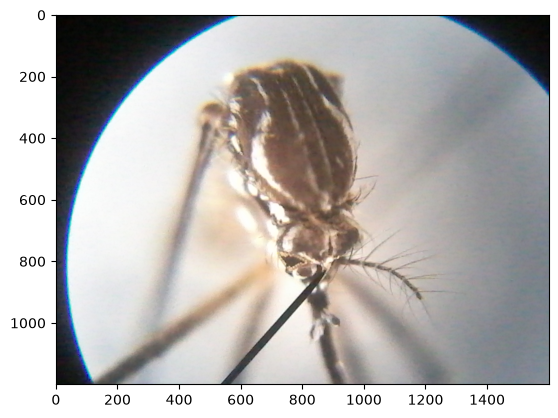

In [4]:
ruta_aegypti = data_path + 'Aedes aegypti/' + os.listdir(data_path + 'Aedes aegypti')[0]
imagen_aegypti = imread(ruta_aegypti)
plt.imshow(imagen_aegypti)


In [5]:
imagen_aegypti.shape


(1200, 1600, 3)

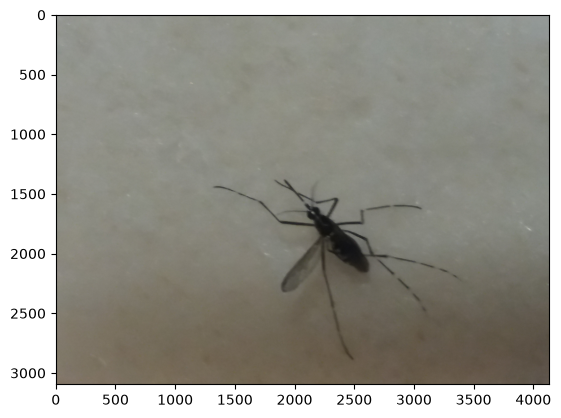

In [6]:
# 2. Visualizamos Aedes albopictus
ruta_albopictus = data_path + 'Aedes albopictus/' + os.listdir(data_path + 'Aedes albopictus')[0]
imagen_albopictus = imread(ruta_albopictus)
plt.imshow(imagen_albopictus)


In [ ]:
imagen_albopictus.shape


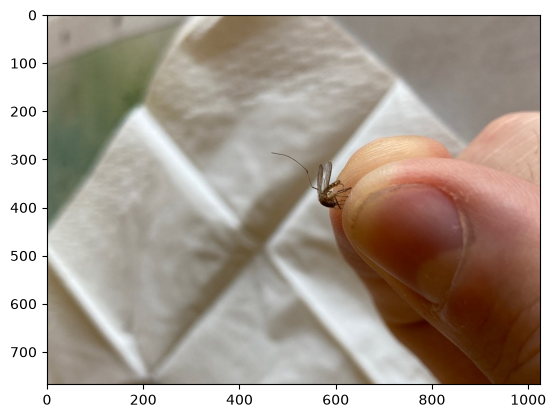

In [7]:
# 3. Visualizamos Culex
ruta_culex = data_path + 'Culex/' + os.listdir(data_path + 'Culex')[0]
imagen_culex = imread(ruta_culex)
plt.imshow(imagen_culex)


In [8]:
imagen_culex.shape


(768, 1024, 3)

**¿Cuántas imágenes tenemos en cada carpeta?**


In [9]:
len(os.listdir(data_path + 'Aedes aegypti'))


1500

In [10]:
len(os.listdir(data_path + 'Aedes albopictus'))


1510

In [11]:
len(os.listdir(data_path + 'Culex'))


932

## 3.2 Dimensiones de las imágenes y tamaño de entrada


In [ ]:
# Definimos el tamaño de entrada de 128x128 
image_shape = (128, 128, 3)
batch_size = 32


# 3.3 Manipulación de imágenes

Rotaciones y tratamientos de las imagenes para un mejor entrenamiento y presición en el resultado


In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [14]:
help(ImageDataGenerator)


Help on class ImageDataGenerator in module keras.src.legacy.preprocessing.image:

class ImageDataGenerator(builtins.object)
 |  ImageDataGenerator(
 |      featurewise_center=False,
 |      samplewise_center=False,
 |      featurewise_std_normalization=False,
 |      samplewise_std_normalization=False,
 |      zca_whitening=False,
 |      zca_epsilon=1e-06,
 |      rotation_range=0,
 |      width_shift_range=0.0,
 |      height_shift_range=0.0,
 |      brightness_range=None,
 |      shear_range=0.0,
 |      zoom_range=0.0,
 |      channel_shift_range=0.0,
 |      fill_mode='nearest',
 |      cval=0.0,
 |      horizontal_flip=False,
 |      vertical_flip=False,
 |      rescale=None,
 |      preprocessing_function=None,
 |      data_format=None,
 |      validation_split=0.0,
 |      interpolation_order=1,
 |      dtype=None
 |  )
 |
 |  DEPRECATED.
 |
 |  Methods defined here:
 |
 |  __init__(
 |      self,
 |      featurewise_center=False,
 |      samplewise_center=False,
 |      featur

In [15]:
image_gen = ImageDataGenerator(rotation_range=20, # rotación máxima de 20º (depende del caso de uso)
                               width_shift_range=0.10, # Desplazamiento en la anchura máximo del 10%
                               height_shift_range=0.10, # Desplazamiento en la altura máximo del 10%
                               rescale=1/255, # Reescalar la imagen para normalizarla entre 0-1
                               shear_range=0.1, # Distorsión de perspectiva (máx 10%)
                               zoom_range=0.1, # Zoom in máximo 10%
                               horizontal_flip=True, # Permitir giro horizontal (espejo)
                               fill_mode='nearest', # Rellenar píxeles vacíos con el más cercano
                               validation_split=0.20 # 20% para validación/test
                              )


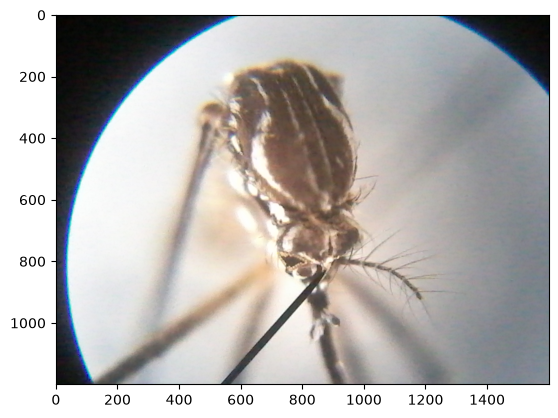

In [16]:
plt.imshow(imagen_aegypti)


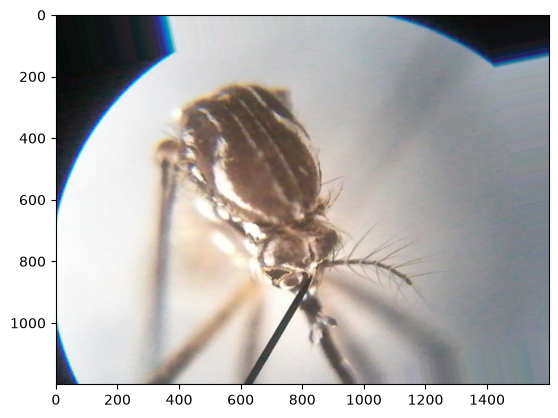

In [17]:
plt.imshow(image_gen.random_transform(imagen_aegypti))


In [18]:
# Generador de entrenamiento (80%)
train_image_gen = image_gen.flow_from_directory(data_path,
                                               target_size=image_shape[:2],
                                               color_mode='rgb',
                                               batch_size=batch_size,
                                               class_mode='categorical',
                                               subset='training',
                                               shuffle=True,
                                               seed=42)


Found 3154 images belonging to 3 classes.


In [19]:
# Generador de prueba / validación (20% restante)
test_datagen = ImageDataGenerator(rescale=1/255, validation_split=0.20)

test_image_gen = test_datagen.flow_from_directory(data_path,
                                                 target_size=image_shape[:2],
                                                 color_mode='rgb',
                                                 batch_size=batch_size,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=False)


Found 788 images belonging to 3 classes.


In [20]:
train_image_gen.class_indices


{'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}

### Cálculo de pesos de clase (Class Weights)
Dado que Culex tiene menor cantidad de imágenes que las especies de Aedes, calculamos pesos de clase para compensar el desbalance durante el entrenamiento.


In [21]:
from sklearn.utils.class_weight import compute_class_weight

clases_train = train_image_gen.classes
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(clases_train),
    y=clases_train
)
class_weights = dict(enumerate(pesos))
class_weights


{0: np.float64(0.8761111111111111),
 1: np.float64(0.8703090507726269),
 2: np.float64(1.4092940125111706)}

# 4.Creación del Modelo
Implementamos la CNN sugerida en los requerimientos del proyecto:
`Conv2D(32) -> MaxPool -> Conv2D(64) -> MaxPool -> Conv2D(128) -> MaxPool -> Flatten -> Dense(128) -> Dropout(0.5) -> Softmax(3)`


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential()

# CAPA CONVOLUCIONAL 1
model.add(Conv2D(filters=32, kernel_size=(3,3), input_shape=image_shape, activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# CAPA CONVOLUCIONAL 2
model.add(Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# CAPA CONVOLUCIONAL 3
model.add(Conv2D(filters=128, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# CAPA FLATTEN: Convierte el mapa de características en un array 1D antes de las capas densas
model.add(Flatten())

# CAPA DENSE INTERMEDIA
model.add(Dense(128, activation='relu'))

# CAPA DROPOUT (reduce sobreajuste desactivando neuronas aleatoriamente)
model.add(Dropout(0.5))

# CAPA FINAL DE CLASIFICACIÓN (3 posibles clases = 3 neuronas con softmax)
model.add(Dense(3, activation='softmax'))

model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])


In [23]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

# 5.Entrenamiento del modelo


In [24]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)


In [25]:
results = model.fit(train_image_gen,
                    epochs=15,
                    validation_data=test_image_gen,
                    callbacks=[early_stop],
                    class_weight=class_weights)


Epoch 1/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.4759 - loss: 0.9215 - val_accuracy: 0.4505 - val_loss: 0.9986
Epoch 2/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.5434 - loss: 0.7465 - val_accuracy: 0.5165 - val_loss: 0.9445
Epoch 3/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.5441 - loss: 0.7295 - val_accuracy: 0.4860 - val_loss: 0.9405
Epoch 4/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.5612 - loss: 0.6579 - val_accuracy: 0.5241 - val_loss: 0.9117
Epoch 5/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.5783 - loss: 0.6258 - val_accuracy: 0.5228 - val_loss: 0.9188
Epoch 6/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - accuracy: 0.5815 - loss: 0.6066 - val_accuracy: 0.5203 - val_loss: 0.8961
Epoch 7/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.5881 - loss: 0.6169 - val_accuracy: 0.5393 - val_loss: 0.9417
Epoch 8/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.6018 - loss: 0.5751 - val_accuracy: 0.5089 - v

In [26]:
import os
os.makedirs('../models', exist_ok=True)
model.save('../models/cnn_propia_mosquitos.h5')
print("Modelo guardado exitosamente en ../models/cnn_propia_mosquitos.h5")


Modelo guardado exitosamente en ../models/cnn_propia_mosquitos.h5


In [27]:
losses = pd.DataFrame(model.history.history)


<Axes: >

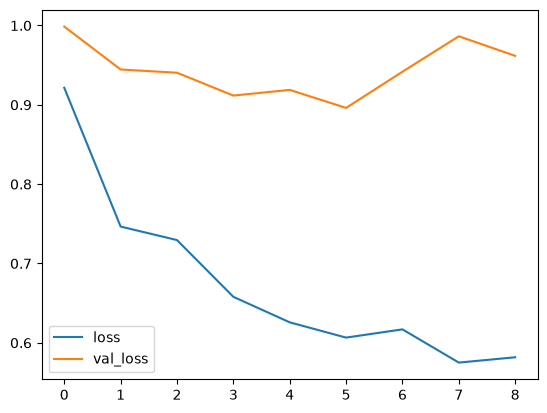

In [28]:
losses[['loss','val_loss']].plot()


<Axes: >

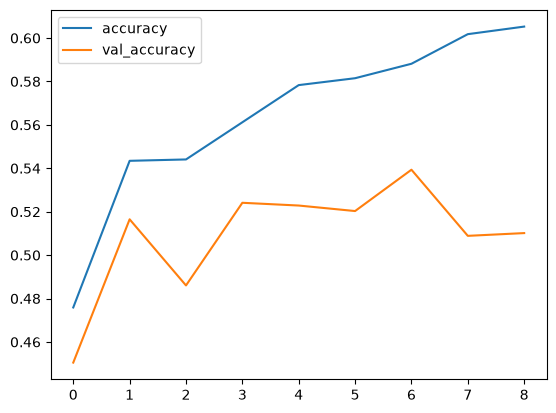

In [29]:
losses[['accuracy','val_accuracy']].plot()


# 6. Evaluación del modelo


## 6.1 Predicción sobre el conjunto de Test


In [30]:
model.metrics_names


['loss', 'compile_metrics']

In [31]:
model.evaluate(test_image_gen)


25/25 ━━━━━━━━━━━━━━━━━━━━ 12s 437ms/step - accuracy: 0.5203 - loss: 0.8961


[0.8961256742477417, 0.5203045606613159]

In [32]:
pred_probabilities = model.predict(test_image_gen)


25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 423ms/step


In [33]:
test_image_gen.classes


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,

In [34]:
predictions = np.argmax(pred_probabilities, axis=-1)
predictions


array([2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 0, 0, 2, 0, 2, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 2, 1, 0, 1, 1, 2, 1, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 2, 2, 0, 1, 0, 0, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 2, 2, 2, 0, 0, 2, 0, 2, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2,

In [35]:
from sklearn.metrics import classification_report, confusion_matrix


In [36]:
print(classification_report(test_image_gen.classes, predictions, target_names=list(test_image_gen.class_indices.keys())))


                  precision    recall  f1-score   support

   Aedes aegypti       0.49      0.66      0.56       300
Aedes albopictus       0.45      0.14      0.21       302
           Culex       0.59      0.91      0.72       186

        accuracy                           0.52       788
       macro avg       0.51      0.57      0.50       788
    weighted avg       0.50      0.52      0.46       788



In [37]:
confusion_matrix(test_image_gen.classes, predictions)


array([[198,  45,  57],
       [198,  42,  62],
       [ 10,   6, 170]])

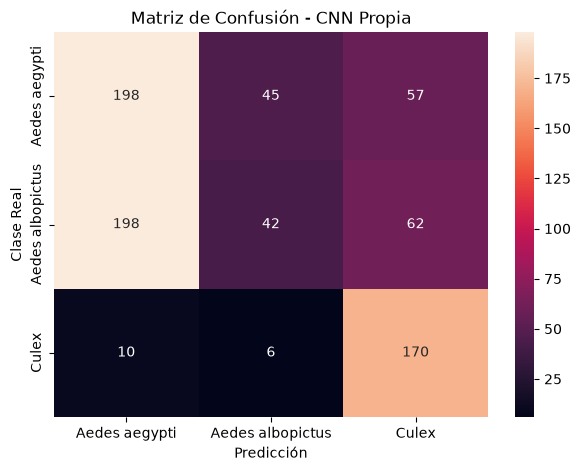

In [38]:
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(test_image_gen.classes, predictions), annot=True, fmt='d',
            xticklabels=list(test_image_gen.class_indices.keys()),
            yticklabels=list(test_image_gen.class_indices.keys()))
plt.xlabel('Predicción')
plt.ylabel('Clase Real')
plt.title('Matriz de Confusión - CNN Propia')
plt.show()


## 6.2 Comparación con MobileNetV2 (Transfer Learning)
Siguiendo los requerimientos del proyecto, comparamos nuestra CNN propia contra un modelo preentrenado (MobileNetV2) usando Transfer Learning.


In [39]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=image_shape)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(3, activation='softmax')(x)

model_mobilenet = Model(inputs=base_model.input, outputs=output)

model_mobilenet.compile(loss='categorical_crossentropy',
                        optimizer='adam',
                        metrics=['accuracy'])

model_mobilenet.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [40]:
results_mobilenet = model_mobilenet.fit(train_image_gen,
                                      epochs=10,
                                      validation_data=test_image_gen,
                                      callbacks=[early_stop],
                                      class_weight=class_weights)

model_mobilenet.save('../models/cnn_mobilenetv2_mosquitos.h5')


Epoch 1/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.6088 - loss: 0.7661 - val_accuracy: 0.5381 - val_loss: 0.8495
Epoch 2/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 99s 994ms/step - accuracy: 0.6988 - loss: 0.5339 - val_accuracy: 0.5228 - val_loss: 0.8520
Epoch 3/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 96s 972ms/step - accuracy: 0.7175 - loss: 0.4804 - val_accuracy: 0.5571 - val_loss: 0.7748
Epoch 4/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.7188 - loss: 0.4473 - val_accuracy: 0.5330 - val_loss: 0.7746
Epoch 5/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 85s 856ms/step - accuracy: 0.7321 - loss: 0.4309 - val_accuracy: 0.5508 - val_loss: 0.8014
Epoch 6/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 96s 977ms/step - accuracy: 0.7353 - loss: 0.4150 - val_accuracy: 0.5457 - val_loss: 0.7980
Epoch 7/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.7324 - loss: 0.3953 - val_accuracy: 0.5393 - val_loss: 0.8027


In [41]:
pred_mobilenet = np.argmax(model_mobilenet.predict(test_image_gen), axis=-1)
print(classification_report(test_image_gen.classes, pred_mobilenet, target_names=list(test_image_gen.class_indices.keys())))


25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 363ms/step
                  precision    recall  f1-score   support

   Aedes aegypti       0.36      0.10      0.16       300
Aedes albopictus       0.48      0.80      0.60       302
           Culex       0.74      0.78      0.76       186

        accuracy                           0.53       788
       macro avg       0.53      0.56      0.51       788
    weighted avg       0.50      0.53      0.47       788



## 6.3 Predicción para una nueva imagen


In [42]:
ruta_nueva_imagen = data_path + 'Aedes aegypti/' + os.listdir(data_path + 'Aedes aegypti')[10]


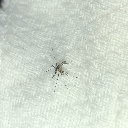

In [43]:
from tensorflow.keras.preprocessing import image

nueva_imagen = image.load_img(ruta_nueva_imagen, target_size=image_shape[:2])
nueva_imagen


In [44]:
type(nueva_imagen)


PIL.Image.Image

In [45]:
nueva_imagen = image.img_to_array(nueva_imagen)


In [46]:
nueva_imagen.shape


(128, 128, 3)

In [47]:
nueva_imagen = np.expand_dims(nueva_imagen, axis=0) / 255.0
nueva_imagen.shape


(1, 128, 128, 3)

In [48]:
model.predict(nueva_imagen)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step


array([[0.12482826, 0.11057579, 0.7645959 ]], dtype=float32)

In [49]:
test_image_gen.class_indices


{'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}